In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image

from pathlib import Path
from huggingface_hub import login
from huggingface_hub import hf_hub_download
from sklearn.model_selection import train_test_split

In [5]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [6]:
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Nexar_Crash_Prediction"
)

DATASET_DIR = (
    PROJECT_ROOT / "dataset" / "Nexar_DashCam_Dataset"
)

OUTPUT_DIR = PROJECT_ROOT / "outputs"
MODELS_DIR = PROJECT_ROOT / "models"

for directory in [
    PROJECT_ROOT,
    OUTPUT_DIR,
    MODELS_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

print("Project root:", PROJECT_ROOT)
print("Dataset directory:", DATASET_DIR)
print("Dataset exists:", DATASET_DIR.exists())

Project root: /content/drive/MyDrive/Nexar_Crash_Prediction
Dataset directory: /content/drive/MyDrive/Nexar_Crash_Prediction/dataset/Nexar_DashCam_Dataset
Dataset exists: False


In [8]:
login()

In [11]:
REPO_ID = "nexar-ai/nexar_collision_prediction"

positive_metadata_path = hf_hub_download(
    repo_id=REPO_ID,
    filename="train/positive/metadata.csv",
    repo_type="dataset"
)

negative_metadata_path = hf_hub_download(
    repo_id=REPO_ID,
    filename="train/negative/metadata.csv",
    repo_type="dataset"
)

print("Metadata files downloaded successfully!")

metadata.csv:   0%|          | 0.00/33.3k [00:00<?, ?B/s]

metadata.csv:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Metadata files downloaded successfully!


In [14]:
REPO_ID = "nexar-ai/nexar_collision_prediction"

if "positive_df" not in globals():
    positive_path = hf_hub_download(
        repo_id=REPO_ID,
        filename="train/positive/metadata.csv",
        repo_type="dataset"
    )
    positive_df = pd.read_csv(positive_path)

if "negative_df" not in globals():
    negative_path = hf_hub_download(
        repo_id=REPO_ID,
        filename="train/negative/metadata.csv",
        repo_type="dataset"
    )
    negative_df = pd.read_csv(negative_path)

print("Metadata is ready.")

Metadata is ready.


In [16]:
positive_data = positive_df.copy()
negative_data = negative_df.copy()

positive_data["label"] = 1
negative_data["label"] = 0

all_videos = pd.concat(
    [positive_data, negative_data],
    ignore_index=True
)

all_videos = all_videos.drop_duplicates(
    subset="file_name"
).reset_index(drop=True)

train_videos, val_videos = train_test_split(
    all_videos,
    test_size=0.2,
    random_state=42,
    stratify=all_videos["label"]
)

train_videos = train_videos.copy()
val_videos = val_videos.copy()

train_videos["split"] = "train"
val_videos["split"] = "validation"

video_split = pd.concat(
    [train_videos, val_videos],
    ignore_index=True
)

OUTPUT_DIR = Path("/content/nexar_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

video_split.to_csv(
    OUTPUT_DIR / "video_split.csv",
    index=False
)

print("Train videos:", len(train_videos))
print("Validation videos:", len(val_videos))

Train videos: 1200
Validation videos: 300


In [17]:
train_ids = set(train_videos["file_name"])
val_ids = set(val_videos["file_name"])

overlap = train_ids.intersection(val_ids)

print("Overlapping videos:", len(overlap))

print("\nClass distribution:")
display(
    video_split.groupby(
        ["split", "label"]
    ).size().unstack(fill_value=0)
)

Overlapping videos: 0

Class distribution:


label,0,1
split,,
train,600,600
validation,150,150


In [18]:
OUTPUT_DIR = Path("/content/nexar_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OBSERVATION_WINDOW = 4.0
PREDICTION_HORIZON = 1.0
WINDOW_STRIDE = 1.0

COARSE_FPS = 1
MEDIUM_FPS = 2
FINE_FPS = 4

IMAGE_SIZE = (224, 224)

sampling_config = {
    "observation_window": OBSERVATION_WINDOW,
    "prediction_horizon": PREDICTION_HORIZON,
    "window_stride": WINDOW_STRIDE,
    "coarse_fps": COARSE_FPS,
    "medium_fps": MEDIUM_FPS,
    "fine_fps": FINE_FPS,
    "image_size": IMAGE_SIZE
}

print("Sampling configuration:")
for key, value in sampling_config.items():
    print(f"{key}: {value}")


Sampling configuration:
observation_window: 4.0
prediction_horizon: 1.0
window_stride: 1.0
coarse_fps: 1
medium_fps: 2
fine_fps: 4
image_size: (224, 224)


In [19]:

SPLIT_FILE = OUTPUT_DIR / "video_split.csv"

if not SPLIT_FILE.exists():
    raise FileNotFoundError(
        f"Split file not found: {SPLIT_FILE}"
    )

video_split = pd.read_csv(SPLIT_FILE)

required_columns = {"file_name", "label", "split"}

missing_columns = required_columns - set(video_split.columns)

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

train_videos = video_split[
    video_split["split"] == "train"
].copy()

val_videos = video_split[
    video_split["split"] == "validation"
].copy()

print("Video split loaded successfully.")
print(f"Training videos: {len(train_videos)}")
print(f"Validation videos: {len(val_videos)}")

print("\nClass distribution:")
print(
    video_split.groupby(["split", "label"])
    .size()
    .unstack(fill_value=0)
)


Video split loaded successfully.
Training videos: 1200
Validation videos: 300

Class distribution:
label         0    1
split               
train       600  600
validation  150  150


In [20]:
REPO_ID = "nexar-ai/nexar_collision_prediction"

positive_candidates = train_videos[
    train_videos["label"] == 1
].copy()

positive_candidates["time_of_event"] = pd.to_numeric(
    positive_candidates["time_of_event"],
    errors="coerce"
)

positive_candidates = positive_candidates[
    positive_candidates["time_of_event"] >= 4.5
]

if positive_candidates.empty:
    raise ValueError("No suitable positive training video was found.")

sample_video = positive_candidates.iloc[0]

file_name = sample_video["file_name"]
event_time = float(sample_video["time_of_event"])

decision_time = event_time - 0.5

video_repo_path = f"train/positive/{file_name}"

video_path = hf_hub_download(
    repo_id=REPO_ID,
    filename=video_repo_path,
    repo_type="dataset"
)

print("Sample video selected and downloaded.")
print(f"File name: {file_name}")
print(f"Event time: {event_time:.3f} seconds")
print(f"Decision time: {decision_time:.3f} seconds")
print(f"Time to accident: {event_time - decision_time:.3f} seconds")
print(f"Video path: {video_path}")


train/positive/00780.mp4: reconstructing file:   0%|          |  0.00B / 13.2MB            

train/positive/00780.mp4: downloading bytes:           |  0.00B            

Sample video selected and downloaded.
File name: 00780.mp4
Event time: 19.967 seconds
Decision time: 19.467 seconds
Time to accident: 0.500 seconds
Video path: /root/.cache/huggingface/hub/datasets--nexar-ai--nexar_collision_prediction/snapshots/7535d0656dac31d7da2846913bb69c6331d2a70a/train/positive/00780.mp4


In [21]:
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise RuntimeError("Could not open the video.")

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
duration = total_frames / fps if fps > 0 else 0

print("Video properties:")
print(f"FPS: {fps:.2f}")
print(f"Total frames: {total_frames}")
print(f"Width: {width}")
print(f"Height: {height}")
print(f"Duration: {duration:.2f} seconds")

cap.release()


Video properties:
FPS: 30.00
Total frames: 1202
Width: 1280
Height: 720
Duration: 40.07 seconds


In [23]:
start_time = decision_time - OBSERVATION_WINDOW
end_time = decision_time

fine_timestamps = np.arange(
    start_time,
    end_time,
    1.0 / FINE_FPS
)

cap = cv2.VideoCapture(video_path)

fine_frames = []

for timestamp in fine_timestamps:

    frame_index = int(round(timestamp * fps))

    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_index)
    success, frame = cap.read()

    if not success:
        continue

    frame = cv2.resize(frame, IMAGE_SIZE)
    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    fine_frames.append(frame)

cap.release()

fine_frames = np.array(fine_frames, dtype=np.uint8)

medium_indices = np.arange(0, len(fine_frames), 2)
coarse_indices = np.arange(0, len(fine_frames), 4)

medium_frames = fine_frames[medium_indices]
coarse_frames = fine_frames[coarse_indices]

print("Multi-scale sampling completed.")
print(f"Fine frames: {len(fine_frames)}")
print(f"Medium frames: {len(medium_frames)}")
print(f"Coarse frames: {len(coarse_frames)}")
print(f"Frame shape: {fine_frames.shape[1:] if len(fine_frames) else 'No frames'}")


Multi-scale sampling completed.
Fine frames: 16
Medium frames: 8
Coarse frames: 4
Frame shape: (224, 224, 3)


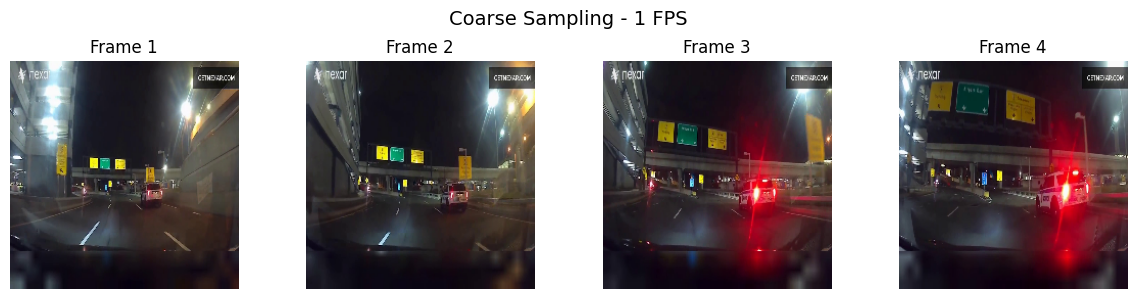

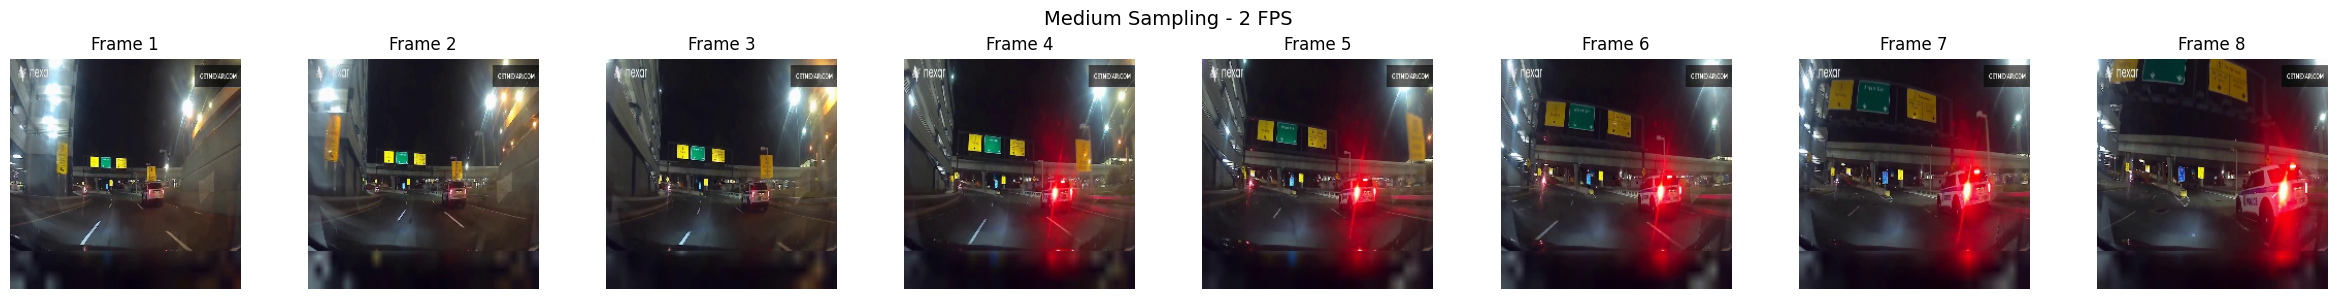

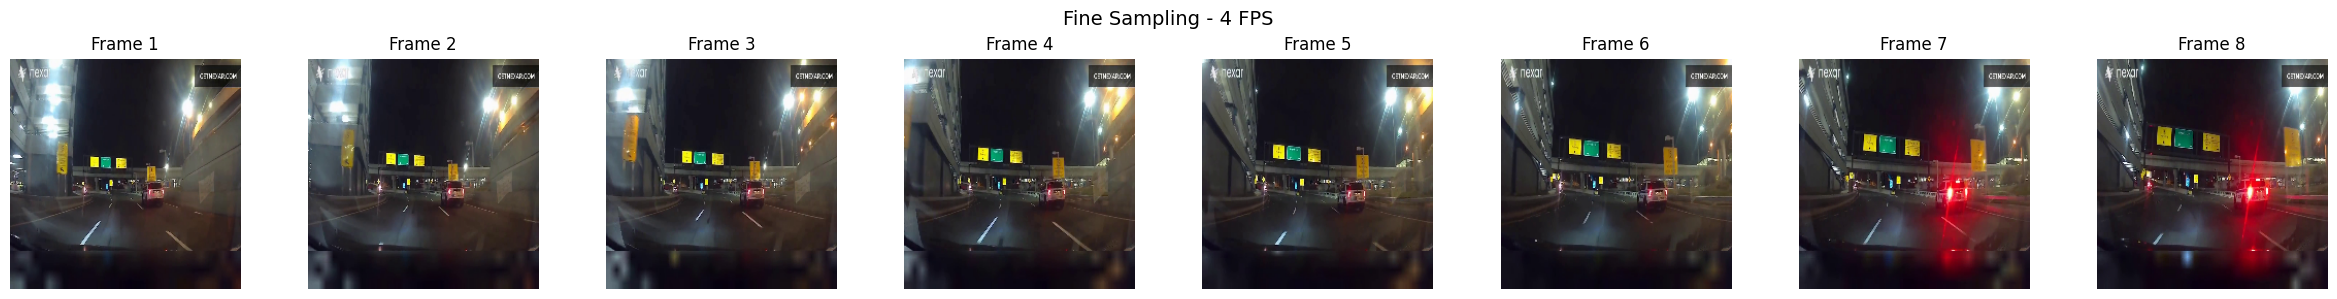

In [25]:
def show_frames(frames, title, max_frames=8):
    n = min(len(frames), max_frames)

    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3))

    if n == 1:
        axes = [axes]

    for i in range(n):
        axes[i].imshow(frames[i])
        axes[i].set_title(f"Frame {i + 1}")
        axes[i].axis("off")

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


show_frames(coarse_frames, "Coarse Sampling - 1 FPS")
show_frames(medium_frames, "Medium Sampling - 2 FPS")
show_frames(fine_frames, "Fine Sampling - 4 FPS")